<a href="https://colab.research.google.com/github/vaishnaviikommidi007/FreshBite/blob/main/NeuralNetworks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
from torchvision import datasets
from torchvision.transforms import ToTensor

# Download the training dataset
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

# Download the testing dataset
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Image shape:", train_data[0][0].shape)
print("First image label:", train_data[0][1])


100%|██████████| 26.4M/26.4M [00:01<00:00, 14.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 229kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.32MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.7MB/s]

Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])
First image label: 9


In [1]:

import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Convert pixel values from 0–255 to 0–1
transform = transforms.ToTensor()

# Load the training dataset
full_train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

# Keep the official test dataset separate
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# Split 60,000 training images into 48,000 and 12,000
train_data, val_data = random_split(
    full_train_data,
    [48000, 12000],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Image shape:", full_train_data[0][0].shape)


100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.7MB/s]

Training images: 48000
Validation images: 12000
Test images: 10000
Image shape: torch.Size([1, 28, 28])


In [2]:

batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


In [3]:

import torch
import torch.nn as nn

class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model = FashionMLP()

print(model)


FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [4]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [5]:

import torch.nn as nn
import torch.optim as optim

# Measures how wrong the model's predictions are
criterion = nn.CrossEntropyLoss()

# Updates the model's weights to reduce the loss
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function and optimizer are ready!")


Loss function and optimizer are ready!


In [6]:

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        # 1. Clear old gradients
        optimizer.zero_grad()

        # 2. Forward propagation
        outputs = model(images)

        # 3. Calculate prediction error
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights and biases
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.4f}"
    )


Epoch [1/5], Loss: 0.5711
Epoch [2/5], Loss: 0.4148
Epoch [3/5], Loss: 0.3711
Epoch [4/5], Loss: 0.3415
Epoch [5/5], Loss: 0.3211


In [7]:

model.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
average_val_loss = val_loss / len(val_loader)

print(f"Validation Accuracy: {accuracy:.2f}%")
print(f"Validation Loss: {average_val_loss:.4f}")


Validation Accuracy: 86.89%
Validation Loss: 0.3581


In [8]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {100 * correct / total:.2f}%")


Test Accuracy: 86.34%


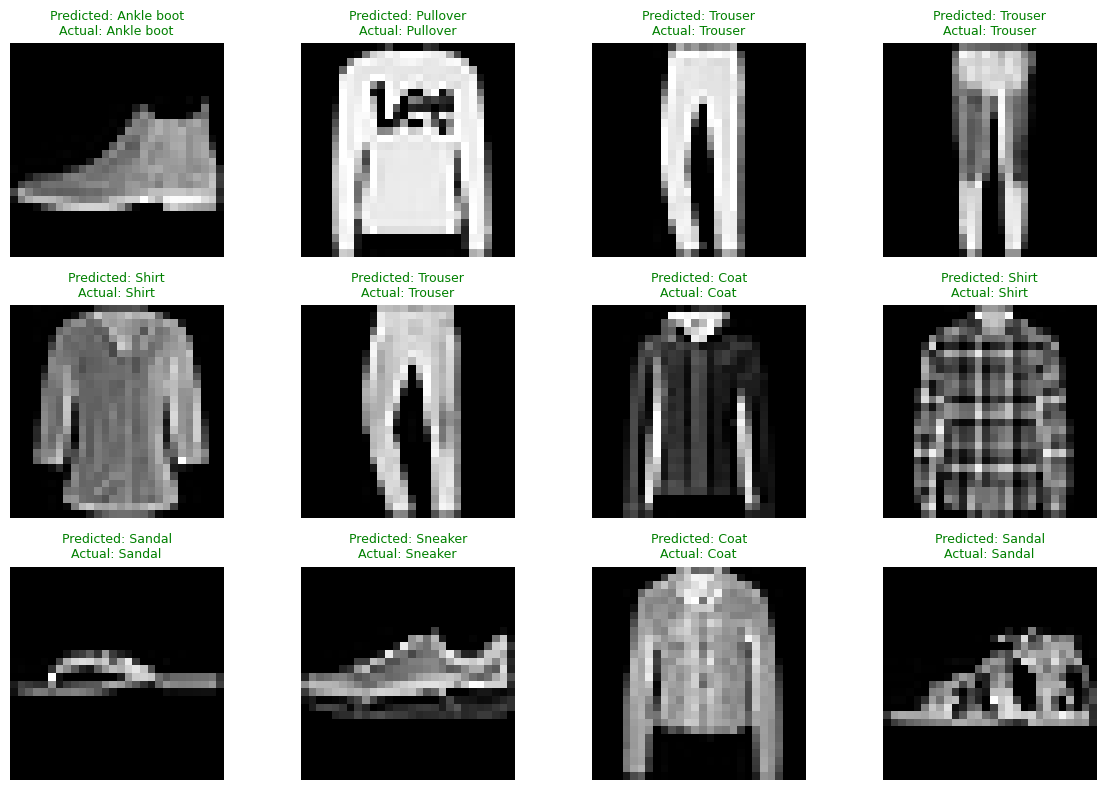

In [9]:

import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Predicted: {predicted}\nActual: {actual}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


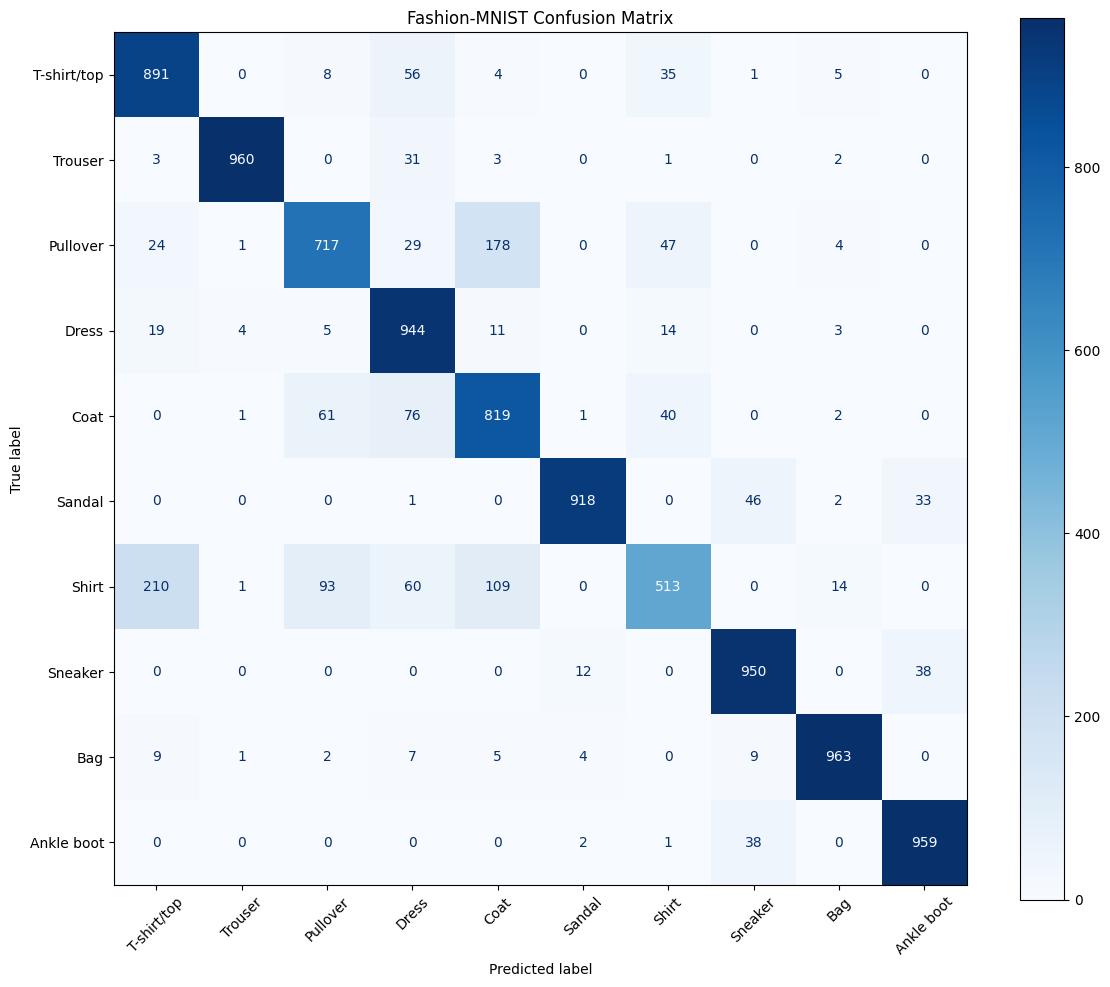

In [10]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:


import torch
import torch.nn as nn

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = FashionCNN()

print(cnn_model)



FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [13]:

images, labels = next(iter(train_loader))

outputs = cnn_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)


Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [14]:

epochs = 5

for epoch in range(epochs):
    cnn_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward propagation
        outputs = cnn_model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update CNN parameters
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.4f}"
    )


Epoch [1/5], Loss: 2.3052
Epoch [2/5], Loss: 2.3052
Epoch [3/5], Loss: 2.3052
Epoch [4/5], Loss: 2.3052
Epoch [5/5], Loss: 2.3052


In [15]:
# Check whether the CNN parameters are changing
for name, param in cnn_model.named_parameters():
    print(name, param.data.abs().mean().item())

features.0.weight 0.1665504425764084
features.0.bias 0.15087896585464478
features.3.weight 0.04150649160146713
features.3.bias 0.04442411661148071
classifier.1.weight 0.012642922811210155
classifier.1.bias 0.01331029087305069
classifier.3.weight 0.0442531555891037
classifier.3.bias 0.040756043046712875


In [16]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("Optimizer reset for CNN")

Optimizer reset for CNN


In [17]:
cnn_model.eval()

images, labels = next(iter(train_loader))

with torch.no_grad():
    outputs = cnn_model(images)

print("First 5 labels:     ", labels[:5].tolist())
print("First 5 predictions:", outputs.argmax(dim=1)[:5].tolist())
print("Output scores:\n", outputs[:2])

First 5 labels:      [4, 4, 8, 8, 2]
First 5 predictions: [6, 6, 6, 6, 6]
Output scores:
 tensor([[-0.0484,  0.0083, -0.0983, -0.0195, -0.0184, -0.0942,  0.0491,  0.0139,
          0.0349, -0.0852],
        [-0.0351,  0.0010, -0.0869, -0.0317, -0.0136, -0.0781,  0.0610,  0.0255,
          0.0403, -0.0688]])


In [18]:
cnn_model.train()

images, labels = next(iter(train_loader))

param = next(cnn_model.parameters())
before = param.detach().clone()

optimizer.zero_grad()

outputs = cnn_model(images)
loss = criterion(outputs, labels)

loss.backward()

print("Loss:", loss.item())
print("Gradient mean:", param.grad.abs().mean().item())

optimizer.step()

print("Parameter changed:",
      not torch.equal(before, param.detach()))

Loss: 2.307368516921997
Gradient mean: 0.0015764308627694845
Parameter changed: True


In [19]:
epochs = 5

for epoch in range(epochs):
    cnn_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.5389
Epoch [2/5], Loss: 0.3523
Epoch [3/5], Loss: 0.3065
Epoch [4/5], Loss: 0.2710
Epoch [5/5], Loss: 0.2495


In [20]:
cnn_model.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
average_val_loss = val_loss / len(val_loader)

print(f"Validation Accuracy: {accuracy:.2f}%")
print(f"Validation Loss: {average_val_loss:.4f}")

Validation Accuracy: 90.16%
Validation Loss: 0.2697


In [21]:
cnn_model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total
average_test_loss = test_loss / len(test_loader)

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {average_test_loss:.4f}")

Test Accuracy: 89.62%
Test Loss: 0.2865


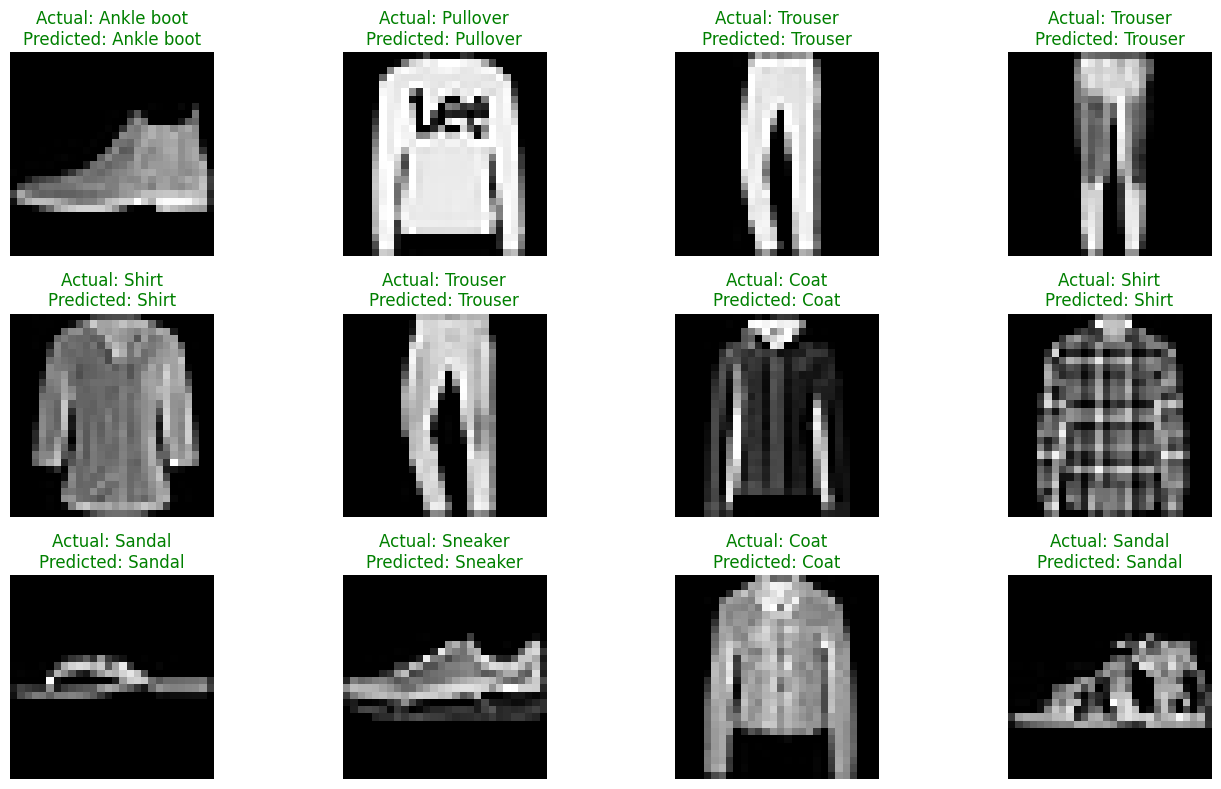

In [22]:
import matplotlib.pyplot as plt

cnn_model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = cnn_model(images)
    predictions = outputs.argmax(dim=1)

plt.figure(figsize=(14, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    image = images[i].squeeze().numpy()
    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    plt.imshow(image, cmap="gray")

    color = "green" if actual == predicted else "red"
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

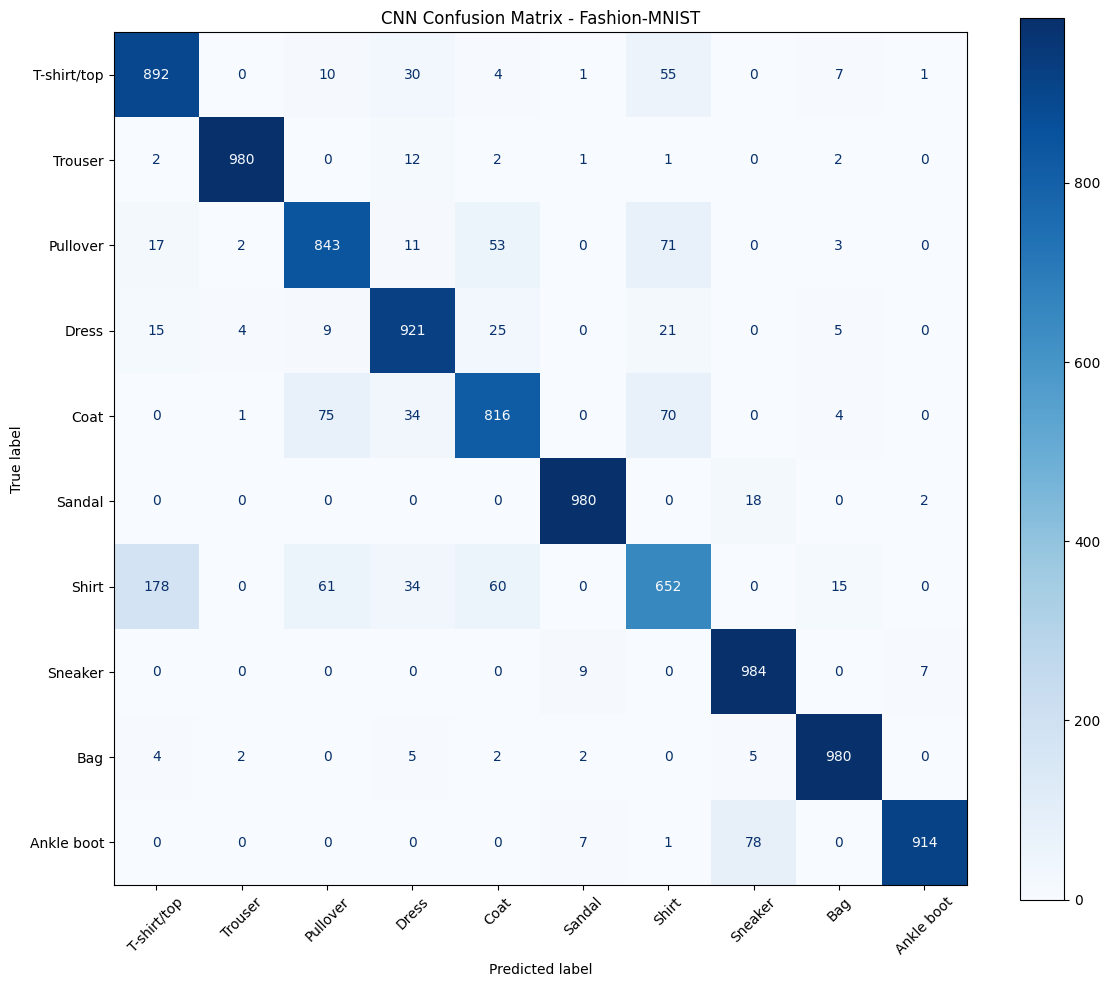

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

cnn_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.numpy())

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix - Fashion-MNIST")
plt.tight_layout()
plt.show()